In [21]:
# Data exploration with the deep learning dataset
import pandas as pd

df = pd.read_csv('/home/madhav/workstation/Lab/experiment/data/DL-PROJECT-DATASET/train.csv')

df.head()

,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128


In [22]:
# Dataset foundational inspection
""" 
Structure of dataframe
image_id,defect_type, mask_rle, dimension
img_1, defect_a,1193 3203
img_1, defect_b,,dim
img_1, defect_c,,dim
img_1, defect_d,,dim

If a image have a defect rle would be not None,
or if it have it would have the value

""" 

# NaN values fill for extraction
df['mask_rle'] = df['mask_rle'].fillna(0)

zero_count = df[
    df['mask_rle'] == 0
].groupby('image_id').size() # series aggrigation

count = (zero_count == 4).sum()
total = (len(df) / 4)

print(f'Total Images : {total} \n Clean Images : {count} \n ratio : {(count/total)*100}')

Total Images : 11393.0 
 Clean Images : 5516 
 ratio : 48.41569384709909


# Foundational data inspection report

With the given dataset, with simple distribution plot about defects, we can observe that most abundant defect is type c, which dominates all other categories into total image count, we can go further with exploring overlaping features set through this dataset.

Inspections
1. Count for each defects : defect c dominates
2. With solo defect occurance count

Images with exclusive 1 defect occurance count : 4679
Images with exclusive 2 defect occurance count : 1072
Images with exclusive 3 defect occurance count : 126


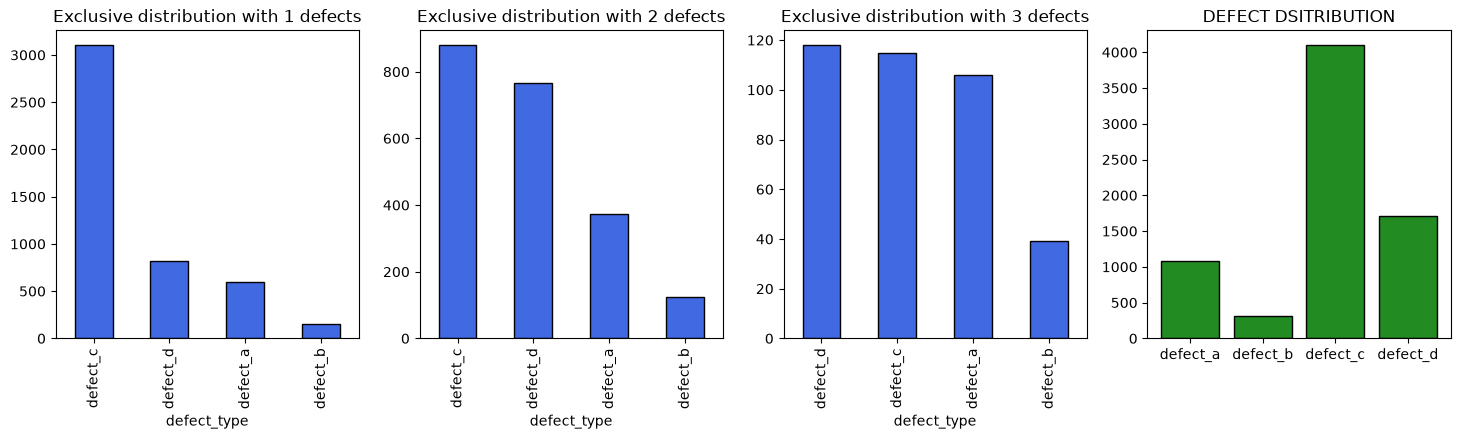

In [23]:
# Defects distribution inspection
import matplotlib.pyplot as plt 
import pandas as pd

fig, axs = plt.subplots(1,4, figsize=(18,4))

# How many images consist of defect_a,b,c,d ...
""" 
for each of the defect simply filter length with condition
of their rle being not zero
"""
defects = list(df['defect_type'].unique())
defect_info = {}
for defect in defects:
    defect_count = df[
        df['defect_type'] == defect
    ]['mask_rle'] != 0
    # len used for counting total | sum would get the positives added
    defect_count = defect_count.sum()
    defect_info[defect] = defect_count

x = defect_info.keys()
y = defect_info.values()

axs[3].bar(
    x=x,
    height=y,
    color='forestgreen',
    edgecolor='black'
)

axs[3].set_title('DEFECT DSITRIBUTION')

# INVESTIGATING : DEFECTS DISTRIBUTION
""" 
Switch view through
== 0 > no defect class
!= 0 > Defect containing
"""
with_defects = df[
    df['mask_rle'] != 0
]

# Listing total occurance of each images in filter with_defects
values = with_defects['image_id'].value_counts()

def defect_distribution(values):
    ''' 
    parameters
    values
        A frequency dictionary about images fetched from root df
        containing either images with defect, or clean images

        with defect filter could have images with more then one occurance
        filtered for ploting in functions internal logic
    '''
    for i in range(1, 4):
        exclusive_defects = values[
            values == i
        ] #  Tweak for differnt view about class distribution for the dataset

        exclusive_defect_image_count = len(exclusive_defects)
        print(f"Images with exclusive {i} defect occurance count : {exclusive_defect_image_count}")

        defect_images = with_defects[
            with_defects['image_id'].isin(list(
                exclusive_defects.index
            ))
        ]

        defect_images['defect_type'].value_counts().plot(kind='bar', title=f'Exclusive distribution with {i} defects', ax=axs[i-1], edgecolor='black', color='royalblue')
defect_distribution(values)

In [24]:
# images with more then one defect count
exclusive_defects = values[
    values != 3
]

exclusive_defect_image_count = len(exclusive_defects)
print(f"Images with more then one defect : {exclusive_defect_image_count}")

# Images with no defect
total_images = list(df['image_id'].unique())
count = 0
for image in total_images:
    if not(image in values):
        count += 1
count, len(total_images)

Images with more then one defect : 5751


(5516, 11393)

In [25]:
# Image metadata indexing

from pathlib import Path

root_dir = Path(
    '/home/madhav/workstation/Lab/experiment/data/DL-PROJECT-DATASET/train'
)

meta_information = []

for path in root_dir.iterdir():

    if not path.is_file():
        continue

    meta_information.append({
        'image_id': path.stem,
        'image_path': str(path)
    })

# Image ID-PATH indexing data frame
meta_information = pd.DataFrame(meta_information)

print(f'Total image files: {len(meta_information)}')

Total image files: 11393


## Spatial exclusivity and output head

With the final network emiting its ouput channel, we need to be sure which final output head to use, we use softmax where only one possibility could take place out of all, and use logistic based if multiple could happen at once,

```md
With insepcting the source dataset with pixel level exclusivity we can conclude with this deccission, if one pixel is occupied with more then one defect class then  we would move fro logistics based output head or softmax ( probabilly not)
```

NameError: name 'Image' is not defined

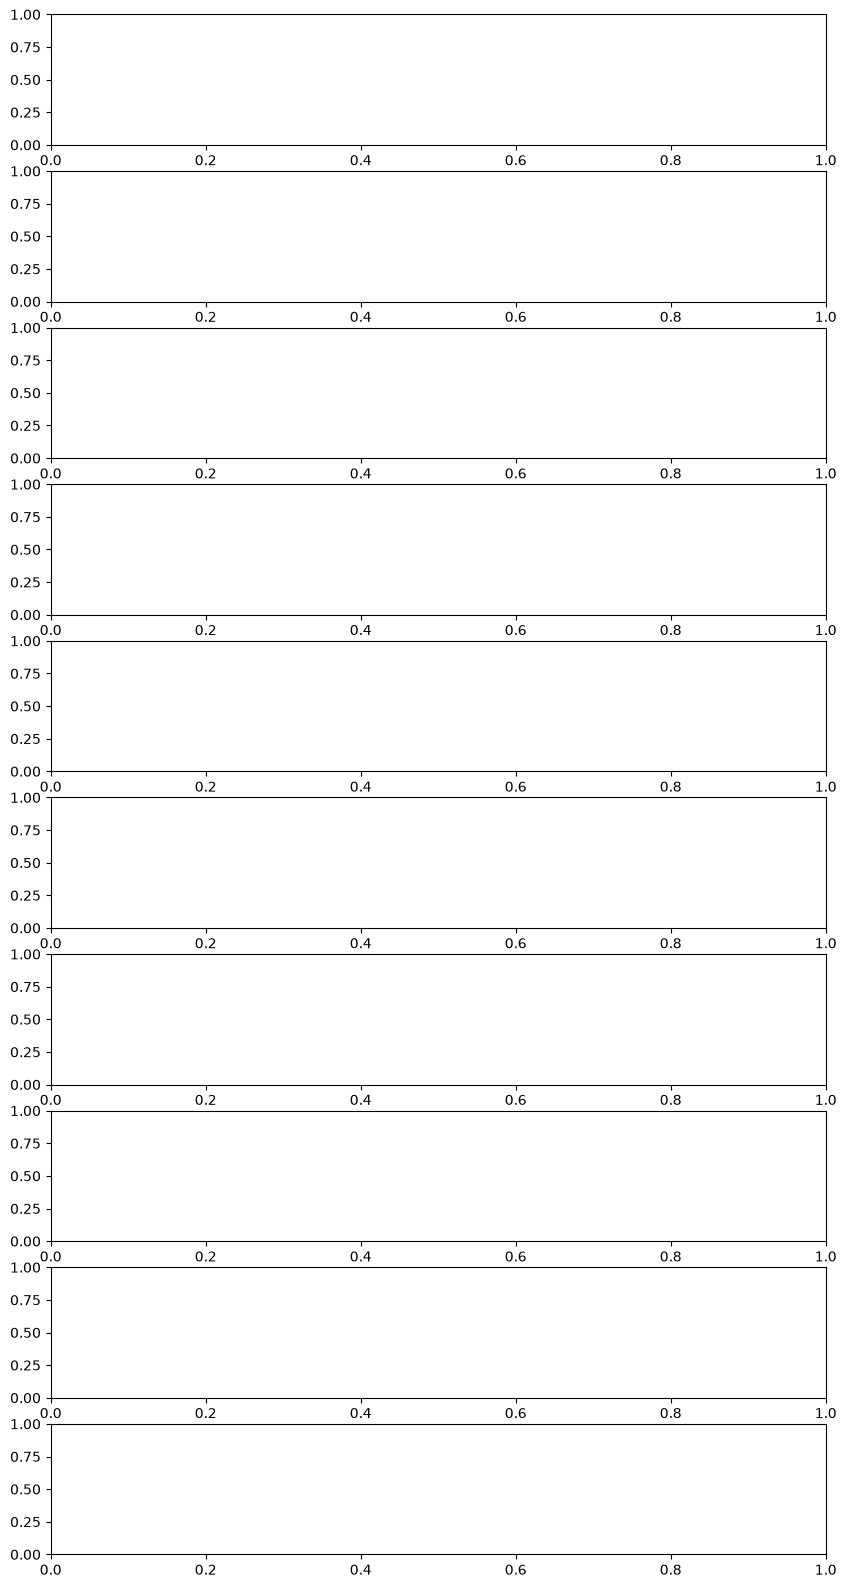

In [26]:
import numpy as np
import pandas as pd

H, W = 128, 800

def rle_decode(rle_str, shape=(H, W)):
    ''' 
    Simple flat based encoder sequence
    with the numebers clamp indexing
    ''' 
    n = shape[0] * shape[1]
    flat = np.zeros(n, dtype=np.uint8)
    if pd.isna(rle_str) or rle_str == 0 or str(rle_str).strip() == "":
        return flat.reshape(shape, order='F')

    tokens = list(map(int, str(rle_str).split()))
    starts  = np.array(tokens[0::2]) - 1      
    lengths = np.array(tokens[1::2])
    ends    = starts + lengths

    for s, e in zip(starts, ends):
        flat[max(s, 0):min(e, n)] = 1

    return flat.reshape(shape, order='F')


fig , axs = plt.subplots(10,1, figsize=(10,20))
i = 0
for encode in encoding[:10]:
    code = rle_decode(encode)
    image = Image.open(path)
    axs[i].imshow(image)
    axs[i].imshow(code, alpha=0.3)
    i += 1